# **MimicFunc / FUNCTO**

**Bài báo 1:** *MimicFunc: Imitating Tool Manipulation from a Single Human Video via Functional Correspondence*.

**Code:** https://github.com/mkt1412/FUNCTO_public






## **1. Tóm tắt phương pháp**

Từ **một video RGB-D người thao tác** (demo, ví dụ: dùng *mug* rót vào *bowl*), hệ thống sinh quỹ đạo cho **một dụng cụ khác** (test, ví dụ: *teapot*) bằng *functional correspondence*:

| Bước (`main.py`) | Module | Việc làm | Mô hình/kỹ thuật |
|---|---|---|---|
| 8 | `cam_to_target_trans.py` | Phát hiện tool + target, tạo mask, fit mặt bàn (RANSAC), đổi sang hệ toạ độ gắn với target | OWL(v2) + SAM, Open3D |
| 9 | `func_point_transfer.py` | Chuyển **function point** (vd. miệng ấm) từ tool demo sang tool test | GPT-4o visual prompting (+ SD-DINO tuỳ chọn) |
| 10 | `grasp_point_transfer.py` | Chuyển **grasp point** (vd. quai ấm) | GPT-4o visual prompting |
| 11 | `tool_pose_transfer.py` | Căn chỉnh pose tool test theo function/grasp/center point | Hình học 3D (+ VLM refine tuỳ chọn) |
| 12 | `tool_traj_transfer.py` | Tối ưu quỹ đạo 6-DoF bám theo quỹ đạo demo, ràng buộc pose đầu/pose tiếp xúc | CasADi |

In [ ]:
import os, sys, time, json, shutil, random, io, contextlib, warnings
import numpy as np
warnings.filterwarnings("ignore")

# ---- Cài đặt thư viện và clone repo (chạy 1 lần) ----
!git clone -q https://github.com/mkt1412/FUNCTO_public.git /content/FUNCTO_public 2>/dev/null || echo "repo đã tồn tại, bỏ qua clone"
!pip -q install open3d casadi pyyaml openai scikit-learn shapely transformers plotly pandas

import torch
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 60.3 MB/s eta 0:00:00
PyTorch: 2.11.0+cu130 | CUDA: True | Tesla T4


## **2. Set up cấu hình**

- `RUN_MODE = "dino"`  **không cần API key**: thay GPT-4o bằng DINOv2 (so khớp đặc trưng giữa điểm demo và các điểm ứng viên).
- `RUN_MODE = "gpt4o"`Cần `OPENAI_API_KEY`.

In [ ]:
RUN_MODE = "dino"        # "dino" | "gpt4o"
SEED = 0
N_GPT_TRIALS = 3

REPO     = os.environ.get("FUNCTO_REPO", "/content/FUNCTO_public")
DEMO_DIR = f"{REPO}/demo_data/pour_demo"
REF_DIR  = "/content/reference/pour_test"        # kết quả gốc của tác giả

def get_openai_key():
    try:
        from google.colab import userdata
        return userdata.get("OPENAI_API_KEY")
    except Exception:
        return os.environ.get("OPENAI_API_KEY")

OPENAI_KEY = get_openai_key()
HAS_KEY = bool(OPENAI_KEY) and not str(OPENAI_KEY).startswith("sk-dummy")

if RUN_MODE == "gpt4o":
    import requests
    assert HAS_KEY, "RUN_MODE='gpt4o' nhưng chưa có OPENAI_API_KEY (thêm vào Colab Secrets)."
    code = requests.get("https://api.openai.com/v1/models",
                        headers={"Authorization": f"Bearer {OPENAI_KEY}"}, timeout=20).status_code
    assert code == 200, f"OpenAI API key không hợp lệ (HTTP {code})"
    print(" OpenAI key hợp lệ")
# vp_utils.py & tool_pose_transfer.py đọc biến môi trường này ngay lúc import,
# nên PHẢI đặt trước khi import code của repo (key giả vẫn đủ ở chế độ 'dino').
os.environ["OPENAI_API_KEY"] = OPENAI_KEY if HAS_KEY else "sk-placeholder-not-used"

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
print("RUN_MODE =", RUN_MODE, "| HAS_KEY =", HAS_KEY)

RUN_MODE = dino | HAS_KEY = False


## **3. Kết quả gốc của tác giả**


In [ ]:
import yaml
os.system(f"git -C {REPO} checkout -- test_data")
if os.path.exists(REF_DIR): shutil.rmtree(REF_DIR)
shutil.copytree(f"{REPO}/test_data/pour_test", REF_DIR)

cfg_path = f"{REPO}/utils_IL/config/config_pour.yaml"
cfg = yaml.safe_load(open(cfg_path))
cfg["paths"]["base_data_path"] = REPO
yaml.safe_dump(cfg, open(cfg_path, "w"))
shutil.copy(cfg_path, f"{REPO}/utils_IL/config/config.yaml")
print(yaml.safe_dump(cfg))
print("Reference files:", len(list(__import__('pathlib').Path(REF_DIR).rglob('*'))))

demo_target_label: bowl
demo_tool_label: mug
params:
  bbox_expansion: 0.05
  iou_thresh: 0.1
  num_candidate_keypoints: 12
  sd_dino_flag: false
  vp_flag: false
paths:
  base_data_path: /content/FUNCTO_public
task_label: pour
test_target_label: bowl
test_tool_label: teapot

Reference files: 56


## 4. **Thay mô hình OWL-ViT, Grounding-SAM, and SD-DINO bằng mô hình chạy cục bộ**
Vì repo gọi OWLv2/SAM/SD-DINO qua server nội bộ (`crane*.d2.comp.nus.edu.sg`) nên không chạy được ngoài trường.
Viết lại `owlv2.py` (OWLv2 thật) và `sam.py` (SAM thật, prompt bằng bbox) giữ nguyên giao diện hàm.

In [ ]:
OWL_SRC = '''
import torch
from PIL import Image
from transformers import Owlv2Processor, Owlv2ForObjectDetection

_CACHE = {}

class OWLViT:
    """OWLv2 chạy cục bộ, giữ nguyên giao diện của repo gốc."""
    def __init__(self, server_url=None, model_name="google/owlv2-base-patch16-ensemble"):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        if model_name not in _CACHE:
            proc = Owlv2Processor.from_pretrained(model_name)
            model = Owlv2ForObjectDetection.from_pretrained(model_name).to(self.device).eval()
            _CACHE[model_name] = (proc, model)
        self.processor, self.model = _CACHE[model_name]

    @torch.no_grad()
    def detect_objects(self, image, text_queries, bbox_score_top_k=20, bbox_conf_threshold=0.1):
        image = image.convert("RGB"); W, H = image.size
        inputs = self.processor(text=[text_queries], images=image, return_tensors="pt").to(self.device)
        outputs = self.model(**inputs)
        # OWLv2 pad ảnh thành hình vuông (đệm ở dưới/phải) -> target_size phải là cạnh vuông
        probs = torch.sigmoid(outputs.logits[0])
        scores, labels = probs.max(dim=-1)
        cx, cy, bw, bh = outputs.pred_boxes[0].unbind(-1)
        boxes = torch.stack([cx - bw/2, cy - bh/2, cx + bw/2, cy + bh/2], dim=-1)
        side = max(W, H)
        keep = (scores > bbox_conf_threshold).nonzero().flatten()
        keep = keep[torch.argsort(scores[keep], descending=True)][:bbox_score_top_k].tolist()
        clip = lambda v: min(max(float(v), 0.0), 1.0)
        out = [{"score": float(scores[i]),
                "bbox": [clip(boxes[i][0].item()*side/W), clip(boxes[i][1].item()*side/H),
                        clip(boxes[i][2].item()*side/W), clip(boxes[i][3].item()*side/H)],
                "box_name": text_queries[int(labels[i])]} for i in keep]
        return out

    def match_by_image(self, *a, **k):
        raise NotImplementedError("không dùng trong demo pour")
'''

SAM_SRC = '''
import numpy as np, torch
from PIL import Image
from transformers import SamModel, SamProcessor

MASK_MODE = "sam"      # "sam" = SAM thật | "box" = mask hình chữ nhật (stub cũ, dùng cho ablation)
_CACHE = {}

class SAM:
    """SAM prompt bằng bbox (bbox chuẩn hoá [x1,y1,x2,y2]) -> list[{'segmentation': bool HxW}]."""
    def __init__(self, server_url=None, model_name="facebook/sam-vit-base"):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        if model_name not in _CACHE:
            _CACHE[model_name] = (SamProcessor.from_pretrained(model_name),
                                  SamModel.from_pretrained(model_name).to(self.device).eval())
        self.processor, self.model = _CACHE[model_name]

    @torch.no_grad()
    def segment_by_bboxes(self, image, bboxes):
        W, H = image.size
        px = [[b[0] * W, b[1] * H, b[2] * W, b[3] * H] for b in bboxes]
        if MASK_MODE == "box":
            out = []
            for x1, y1, x2, y2 in px:
                m = np.zeros((H, W), dtype=bool); m[int(y1):int(y2), int(x1):int(x2)] = True
                out.append({"segmentation": m})
            return out
        inputs = self.processor(image.convert("RGB"), input_boxes=[px], return_tensors="pt").to(self.device)
        outputs = self.model(**inputs, multimask_output=False)
        masks = self.processor.image_processor.post_process_masks(
            outputs.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]
        return [{"segmentation": masks[i, 0].numpy().astype(bool)} for i in range(len(px))]
'''
for fn, src in [("owlv2.py", OWL_SRC), ("sam.py", SAM_SRC)]:
    p = f"{REPO}/cloud_services/apis/{fn}"
    if not os.path.exists(p + ".orig"): shutil.copy(p, p + ".orig")      # giữ bản gốc
    open(p, "w").write(src)
print("Đã ghi owlv2.py và sam.py (bản gốc lưu thành *.orig)")

Đã ghi owlv2.py và sam.py (bản gốc lưu thành *.orig)


**## 5. Dùng DINOv2 thay thế GPT-4o **
Trong bài báo, function/grasp point được chọn bằng **GPT-4o visual prompting**: ảnh tool test được đánh nhãn P1…Pk, GPT-4o chọn nhãn tương ứng với điểm trên tool demo.

Dùng **DINOv2** để lấy đặc trưng dày, chọn ứng viên có **cosine similarity cao nhất** với đặc trưng của điểm demo.

In [ ]:
import torch.nn.functional as F
from PIL import Image
from transformers import AutoModel

class DinoMatcher:
    def __init__(self, name="facebook/dinov2-base", res=448):
        self.dev = "cuda" if torch.cuda.is_available() else "cpu"
        self.model = AutoModel.from_pretrained(name).to(self.dev).eval()
        self.res = res
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    @torch.no_grad()
    def feats(self, pil):
        img = pil.convert("RGB").resize((self.res, self.res), Image.BICUBIC)
        x = torch.from_numpy(np.asarray(img)).float().permute(2, 0, 1)[None] / 255.0
        x = ((x - self.mean) / self.std).to(self.dev)
        tok = self.model(pixel_values=x).last_hidden_state[:, 1:, :]          # bỏ CLS
        g = self.res // 14
        f = tok.reshape(1, g, g, -1).permute(0, 3, 1, 2)
        return F.normalize(f, dim=1)                                           # (1,C,g,g)

    def at(self, f, xy, size):
        """đặc trưng tại điểm xy (pixel của ảnh gốc kích thước size=(w,h)) bằng nội suy bilinear."""
        gx = float(xy[0]) / size[0] * 2 - 1
        gy = float(xy[1]) / size[1] * 2 - 1
        grid = torch.tensor([[[[gx, gy]]]], dtype=f.dtype, device=f.device)
        return F.normalize(F.grid_sample(f, grid, align_corners=False)[0, :, 0, 0], dim=0)

_DINO = None
SEL = {}

def _demo_tool_box():
    x0, y0, x1, y1 = json.load(open(f"{DEMO_DIR}/detection_output/tool.json"))
    return [x0 * 0.95, y0 * 0.95, x1 * 1.03, y1 * 1.03]          # đúng hệ số mở rộng của repo

def _demo_crop_and_point(kind):
    from utils_IL.perception_utils import fit_gaussian
    box = _demo_tool_box()
    crop = Image.open(f"{DEMO_DIR}/rgb/00000.jpg").convert("RGB").crop(box)
    if kind == "function":
        fx, fy = json.load(open(f"{DEMO_DIR}/func_point_track_output/func_point_2d_init.json"))
        pt = [int(fx - box[0]), int(fy - box[1])]
    else:                                                          # lặp lại đúng cách repo tính demo grasp point
        mean, _ = fit_gaussian(json.load(open(f"{DEMO_DIR}/grasp_det_output/grasp_points.json")))
        x, y = int(mean[0]), int(mean[1])
        pt = [y - box[0], x - box[1]]
    return crop, pt

def make_dino_selector(kind):
    from utils_IL.vp_utils import annotate_motion
    def keypoint_transfer(subtask, obs_image_reshaped, annotated_image, candidate_keypoints,
                          prompts=None, debug=False, grasp=False, **kw):
        global _DINO
        if _DINO is None: _DINO = DinoMatcher()
        demo_crop, demo_pt = _demo_crop_and_point(kind)
        cands = candidate_keypoints["grasped"]
        f_demo = _DINO.feats(demo_crop); f_test = _DINO.feats(obs_image_reshaped)
        v_demo = _DINO.at(f_demo, demo_pt, demo_crop.size)
        sims = np.array([float(v_demo @ _DINO.at(f_test, c, obs_image_reshaped.size)) for c in cands])
        idx = int(sims.argmax())
        SEL[kind] = {"idx": idx, "sims": sims.tolist()}
        key = "grasp_keypoint" if grasp else "function_keypoint"
        context = {key: f"P{idx + 1}", "selector": "dinov2"}
        context_cor = {"selected_keypoint": cands[idx]}
        return context, context_cor, annotate_motion(obs_image_reshaped, context_cor, add_caption=False)
    return keypoint_transfer
print("DINO selector sẵn sàng")

DINO selector sẵn sàng


## 6. **`run_pipeline()` gồm 5 stage**



In [ ]:
sys.path.insert(0, REPO); os.chdir(REPO)
import cloud_services.apis.sam as sam_mod
import cam_to_target_trans as m_det
import func_point_transfer as m_func
import grasp_point_transfer as m_grasp
import tool_pose_transfer as m_pose
import tool_traj_transfer as m_traj

ORIG_KT = {"function": m_func.keypoint_transfer, "grasp": m_grasp.keypoint_transfer}   # bản GPT-4o gốc
SELECTORS = {
    "gpt4o": lambda: (ORIG_KT["function"], ORIG_KT["grasp"]),
    "dino":  lambda: (make_dino_selector("function"), make_dino_selector("grasp")),
}
TASK, TOOL, TARGET = cfg["task_label"], cfg["test_tool_label"], cfg["test_target_label"]
print(f"Task: dùng '{TOOL}' để '{TASK}' vào '{TARGET}' (demo dùng '{cfg['demo_tool_label']}')")

def run_pipeline(run_name, selector="dino", n_cand=12, mask_mode="sam", vp_flag=False, verbose=False):
    test_dir = f"{REPO}/test_data/{run_name}"
    if os.path.exists(test_dir): shutil.rmtree(test_dir)
    os.makedirs(test_dir)
    for sub in ["rgb", "depth"]:
        shutil.copytree(f"{REF_DIR}/{sub}", f"{test_dir}/{sub}")
    shutil.copy(f"{REF_DIR}/intrinsic.json", test_dir)

    seed_all()
    sam_mod.MASK_MODE = mask_mode
    SEL.clear()
    m_func.keypoint_transfer, m_grasp.keypoint_transfer = SELECTORS[selector]()

    stages = [
        ("detect+frame", lambda: (m_det.demo_test_deteciton(test_dir, TOOL, TARGET), m_det.cam_to_target_trans(test_dir))),
        ("func_point",   lambda: m_func.func_point_transfer(DEMO_DIR, test_dir, TOOL, TARGET, TASK, n_cand, False)),
        ("grasp_point",  lambda: m_grasp.grasp_point_transfer(DEMO_DIR, test_dir, TOOL, TARGET, TASK, n_cand, False)),
        ("tool_pose",    lambda: m_pose.tool_pose_transfer(DEMO_DIR, test_dir, TOOL, TARGET, TASK, vp_flag)),
        ("trajectory",   lambda: m_traj.tool_trajectory_transfer(DEMO_DIR, test_dir)),
    ]
    res = {"run": run_name, "selector": selector, "n_cand": n_cand, "mask": mask_mode,
           "ok": True, "failed_stage": "", "error": ""}
    for name, fn in stages:
        t0 = time.time(); buf = io.StringIO()
        try:
            with contextlib.redirect_stdout(buf if not verbose else sys.stdout):
                fn()
        except (Exception, SystemExit) as e:                      # SystemExit: repo gọi exit()
            res.update(ok=False, failed_stage=name, error=f"{type(e).__name__}: {str(e)[:150]}")
            res[f"t_{name}"] = time.time() - t0
            break
        res[f"t_{name}"] = time.time() - t0
    res["t_total"] = sum(v for k, v in res.items() if k.startswith("t_"))
    for kind in ("function", "grasp"):                            # độ "tự tin" của DINO: top1 - top2
        if kind in SEL:
            s = sorted(SEL[kind]["sims"], reverse=True)
            res[f"margin_{kind}"] = s[0] - s[1] if len(s) > 1 else np.nan
    return res
print("run_pipeline sẵn sàng")

Task: dùng 'teapot' để 'pour' vào 'bowl' (demo dùng 'mug')
run_pipeline sẵn sàng


## 7. Run pipeline

In [ ]:
import importlib, sys
import cloud_services.apis.owlv2 as owl_mod
import cloud_services.apis.sam as sam_mod
importlib.reload(owl_mod); importlib.reload(sam_mod)

# cam_to_target_trans đã "from ... import OWLViT, SAM" nên phải gắn lại bản mới
import cam_to_target_trans as m_det
m_det.OWLViT = owl_mod.OWLViT
m_det.SAM = sam_mod.SAM

# kiểm tra chắc chắn đã dùng bản mới
import inspect
print("Đã vá:", "post_process_object_detection" not in inspect.getsource(m_det.OWLViT.detect_objects))

Đã vá: True


Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

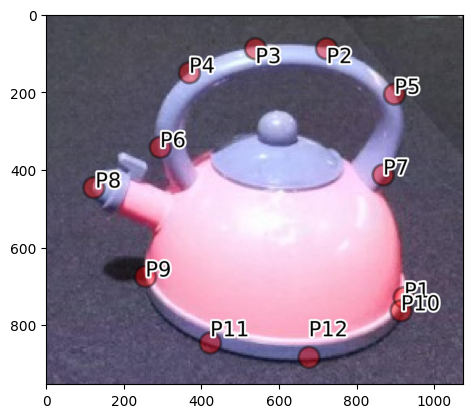

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

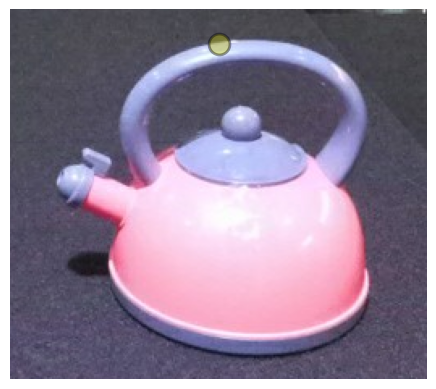

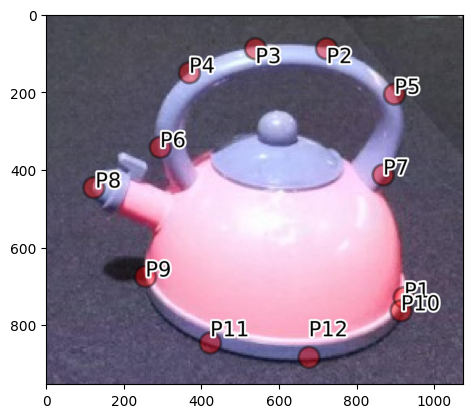

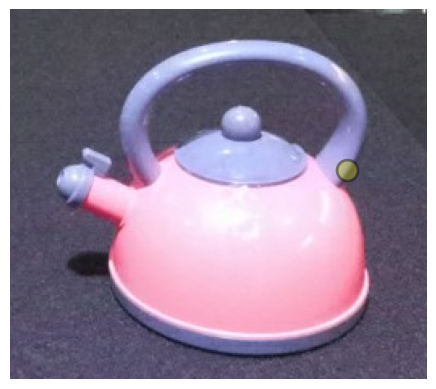

{'run': 'main_dino', 'selector': 'dino', 'n_cand': 12, 'mask': 'sam', 'ok': True, 'failed_stage': '', 'error': '', 't_detect+frame': 7.69, 't_func_point': 5.19, 't_grasp_point': 1.29, 't_tool_pose': 10.04, 't_trajectory': 8.9, 't_total': 33.1, 'margin_function': 0.04, 'margin_grasp': 0.04}


In [ ]:
main_name = f"main_{RUN_MODE}"
r = run_pipeline(main_name, selector=RUN_MODE, n_cand=12, mask_mode="sam", verbose=False)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()})
assert r["ok"], f"Pipeline lỗi ở stage '{r['failed_stage']}': {r['error']}"

## 8. Metric định lượng
Vì chưa có robot, ta đo **độ lệch so với kết quả của tác giả** (reference, *không phải ground-truth tuyệt đối*) + một **proxy hình học cho thành công khi rót**:

| Metric | Ý nghĩa |
|---|---|
| Mask IoU (tool / target) | chất lượng detection+segmentation so với mask của tác giả |
| Function / Grasp point error (% đường chéo bbox tool) | điểm chuyển đúng chỗ hay không |
| Traj. position error (m) / rotation error (°) | quỹ đạo 54 pose lệch bao nhiêu so với của tác giả |
| Pour proxy | tại pose tiếp xúc, function point nằm **trong diện tích bbox của bowl** (xy) → "đổ trúng bowl" |

In [ ]:
import pandas as pd
from IPython.display import display
from scipy.spatial.transform import Rotation as Rot

def _j(p): return json.load(open(p))
def _iou(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return float((a & b).sum() / max((a | b).sum(), 1)) if a.shape == b.shape else np.nan
def load_traj(p):
    t = _j(p); return np.array([x[0] for x in t]), np.array([x[1] for x in t])

def evaluate(run_name, ref=REF_DIR):
    d = f"{REPO}/test_data/{run_name}"; m = {}
    try:
        m["iou_tool"]   = _iou(np.load(f"{d}/detection_output/tool_mask.npy"),   np.load(f"{ref}/detection_output/tool_mask.npy"))
        m["iou_target"] = _iou(np.load(f"{d}/detection_output/target_mask.npy"), np.load(f"{ref}/detection_output/target_mask.npy"))
        x0, y0, x1, y1 = _j(f"{ref}/detection_output/tool.json"); diag = float(np.hypot(x1 - x0, y1 - y0))
        for kind, rel in [("func", "func_point_transfer_output/test_init_frame_func_point_out.json"),
                          ("grasp", "grasp_transfer_output/test_init_frame_grasp_point_out.json")]:
            m[f"{kind}_err_%diag"] = 100 * float(np.linalg.norm(np.array(_j(f"{d}/{rel}")) - np.array(_j(f"{ref}/{rel}")))) / diag
        (Pa, Ea), (Pb, Eb) = load_traj(f"{d}/tool_traj_transfer_output/test_tool_trajectory.json"), \
                             load_traj(f"{ref}/tool_traj_transfer_output/test_tool_trajectory.json")
        n = min(len(Pa), len(Pb))
        m["traj_pos_err_m"]  = float(np.linalg.norm(Pa[:n] - Pb[:n], axis=1).mean())
        m["traj_rot_err_deg"] = float(np.degrees((Rot.from_euler("xyz", Ea[:n]).inv() * Rot.from_euler("xyz", Eb[:n])).magnitude()).mean())
        trk = _j(f"{d}/tool_pose_transfer_output/test_tool_track.json")
        dim = _j(f"{d}/cam_to_target_trans_output/cam_to_target_trans.json")["target_dim"]
        fx, fy, _ = trk["function_func"]
        off = max(abs(fx) / (dim[0] / 2), abs(fy) / (dim[1] / 2))
        m["pour_offset"] = off                 # <=1: function point nằm trong footprint của bowl
        m["pour_proxy_ok"] = bool(off <= 1.0)
    except Exception as e:
        m["eval_error"] = f"{type(e).__name__}: {e}"
    return m

row = {**r, **evaluate(main_name)}
main_df = pd.DataFrame([row]).T
display(main_df)

,0
run,main_dino
selector,dino
n_cand,12
mask,sam
ok,True
failed_stage,
error,
t_detect+frame,7.686081
t_func_point,5.192199
t_grasp_point,1.285969


## 9. Trực quan hoá kết quả
### 9.1 Detection → segmentation → chọn function/grasp point

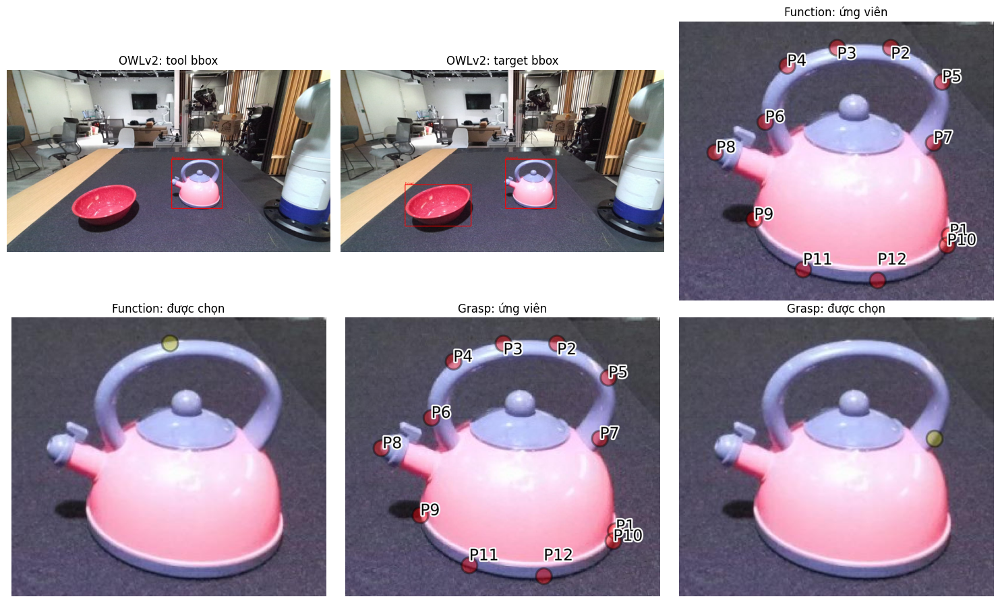

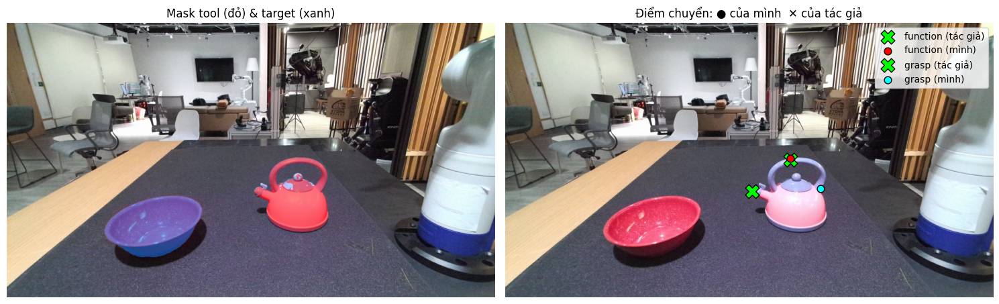

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

def show_run(name):
    d = f"{REPO}/test_data/{name}"
    panels = [("OWLv2: tool bbox", "detection_output/tool_bbox.png"),
              ("OWLv2: target bbox", "detection_output/target_bbox.png"),
              ("Function: ứng viên", "func_point_transfer_output/visual_prompting_candidates.png"),
              ("Function: được chọn", "func_point_transfer_output/visual_prompting_result.png"),
              ("Grasp: ứng viên", "grasp_transfer_output/visual_prompting_candidates.png"),
              ("Grasp: được chọn", "grasp_transfer_output/visual_prompting_result.png")]
    fig, ax = plt.subplots(2, 3, figsize=(15, 9))
    for a, (t, rel) in zip(ax.ravel(), panels):
        p = f"{d}/{rel}"
        if os.path.exists(p): a.imshow(Image.open(p))
        a.set_title(t); a.axis("off")
    plt.tight_layout(); plt.show()

def overlay_points(name, ref=REF_DIR):
    d = f"{REPO}/test_data/{name}"
    img = np.array(Image.open(f"{d}/rgb/00000.jpg").convert("RGB")).copy()
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    ov = img.copy().astype(float)
    for part, col in [("tool", (255, 0, 0)), ("target", (0, 120, 255))]:
        mk = np.load(f"{d}/detection_output/{part}_mask.npy").astype(bool)
        ov[mk] = 0.5 * ov[mk] + 0.5 * np.array(col)
    ax[0].imshow(ov.astype(np.uint8)); ax[0].set_title("Mask tool (đỏ) & target (xanh)")
    ax[1].imshow(img); ax[1].set_title("Điểm chuyển: ● của mình  ✕ của tác giả")
    for kind, rel, c in [("function", "func_point_transfer_output/test_init_frame_func_point_out.json", "red"),
                         ("grasp", "grasp_transfer_output/test_init_frame_grasp_point_out.json", "cyan")]:
        mine, theirs = _j(f"{d}/{rel}"), _j(f"{ref}/{rel}")
        ax[1].scatter(*theirs, c="lime", marker="X", s=220, edgecolors="k", label=f"{kind} (tác giả)")
        ax[1].scatter(*mine, c=c, s=60, edgecolors="k", zorder=5, label=f"{kind} (mình)")
    ax[1].legend(); [a.axis("off") for a in ax]; plt.tight_layout(); plt.show()

show_run(main_name); overlay_points(main_name)

### 9.2 Quỹ đạo 3D

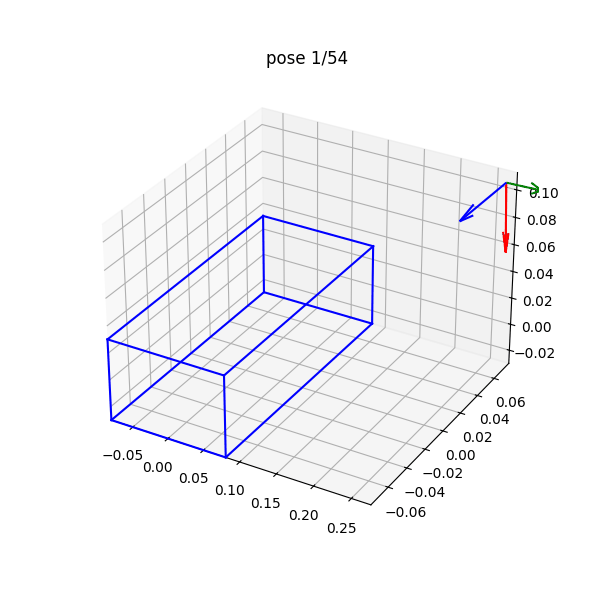

In [ ]:
import plotly.graph_objects as go
import open3d as o3d

def box_edges(pts):
    lo, hi = pts.min(0), pts.max(0)
    c = np.array([[x, y, z] for x in (lo[0], hi[0]) for y in (lo[1], hi[1]) for z in (lo[2], hi[2])])
    e = [(i, j) for i in range(8) for j in range(i + 1, 8) if (np.abs(c[i] - c[j]) > 1e-9).sum() == 1]
    return c, e

def plot_traj_3d(name, ref=REF_DIR, max_pts=25000):
    d = f"{REPO}/test_data/{name}"
    P, E = load_traj(f"{d}/tool_traj_transfer_output/test_tool_trajectory.json")
    Pr, _ = load_traj(f"{ref}/tool_traj_transfer_output/test_tool_trajectory.json")
    pcd = o3d.io.read_point_cloud(f"{d}/tool_traj_transfer_output/test_tool_traj_pc.ply")
    pts, col = np.asarray(pcd.points), np.clip(np.asarray(pcd.colors), 0, 1)
    sel = np.random.RandomState(0).choice(len(pts), min(max_pts, len(pts)), replace=False)
    fig = go.Figure()
    fig.add_trace(go.Scatter3d(x=pts[sel, 0], y=pts[sel, 1], z=pts[sel, 2], mode="markers",
                               marker=dict(size=1.5, color=[f"rgb({int(r*255)},{int(g*255)},{int(b*255)})" for r, g, b in col[sel]]),
                               name="scene + tool", hoverinfo="skip"))
    fig.add_trace(go.Scatter3d(x=P[:, 0], y=P[:, 1], z=P[:, 2], mode="lines+markers",
                               line=dict(width=6, color="red"), marker=dict(size=3, color=np.arange(len(P)), colorscale="Turbo"),
                               name="quỹ đạo của mình"))
    fig.add_trace(go.Scatter3d(x=Pr[:, 0], y=Pr[:, 1], z=Pr[:, 2], mode="lines",
                               line=dict(width=4, color="lime", dash="dash"), name="quỹ đạo tác giả"))
    corners, edges = box_edges(np.array(_j(f"{d}/cam_to_target_trans_output/cam_to_target_trans.json")["box_points"]))
    for i, j in edges:
        fig.add_trace(go.Scatter3d(x=[corners[i, 0], corners[j, 0]], y=[corners[i, 1], corners[j, 1]],
                                   z=[corners[i, 2], corners[j, 2]], mode="lines", line=dict(color="blue", width=4), showlegend=False))
    fig.update_layout(title=f"Quỹ đạo tool ({name})", scene=dict(aspectmode="data"), margin=dict(l=0, r=0, b=0, t=40), height=650)
    fig.show()

def make_gif(name, out="/content/traj.gif", fps=10):
    import matplotlib.animation as animation
    d = f"{REPO}/test_data/{name}"
    P, E = load_traj(f"{d}/tool_traj_transfer_output/test_tool_trajectory.json")
    corners, edges = box_edges(np.array(_j(f"{d}/cam_to_target_trans_output/cam_to_target_trans.json")["box_points"]))
    lo, hi = np.minimum(P.min(0), corners.min(0)), np.maximum(P.max(0), corners.max(0))
    fig = plt.figure(figsize=(6, 6)); ax = fig.add_subplot(111, projection="3d")
    def upd(i):
        ax.cla(); ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        for a, b in edges: ax.plot(*zip(corners[a], corners[b]), c="b")
        ax.plot(P[:i + 1, 0], P[:i + 1, 1], P[:i + 1, 2], c="r")
        R = Rot.from_euler("xyz", E[i]).as_matrix()
        for k, c in enumerate("rgb"): ax.quiver(*P[i], *(R[:, k] * 0.05), color=c)
        ax.set_title(f"pose {i + 1}/{len(P)}")
    ani = animation.FuncAnimation(fig, upd, frames=len(P), interval=1000 // fps)
    ani.save(out, writer=animation.PillowWriter(fps=fps)); plt.close(fig); return out

plot_traj_3d(main_name)
from IPython.display import Image as IPImage
display(IPImage(make_gif(main_name)))

### 9.3 Trực quan từng bước của pipeline
Mỗi hàm `viz_*` đọc file output của đúng stage đó, nên có thể gọi riêng sau khi stage chạy xong (hoặc `viz_all(run_name)` để xem cả 5 bước).

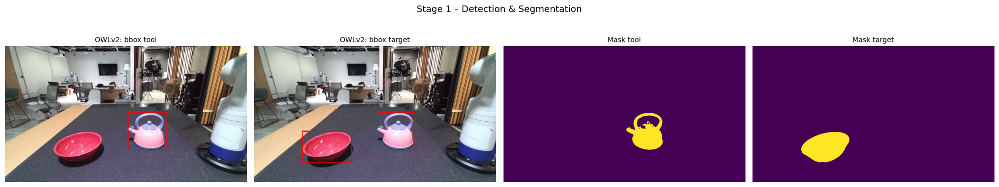

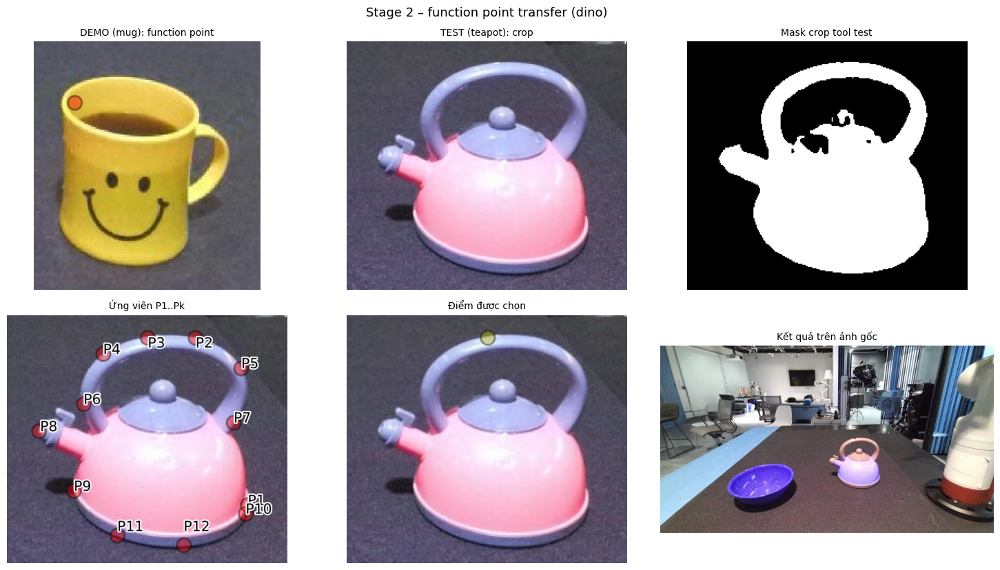

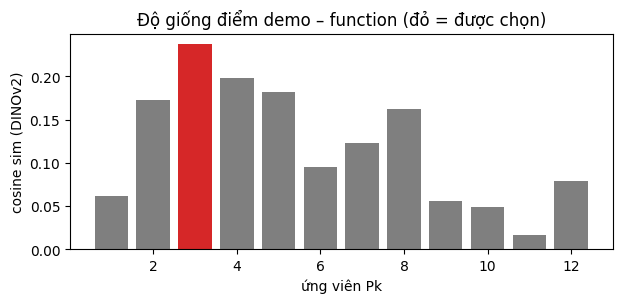

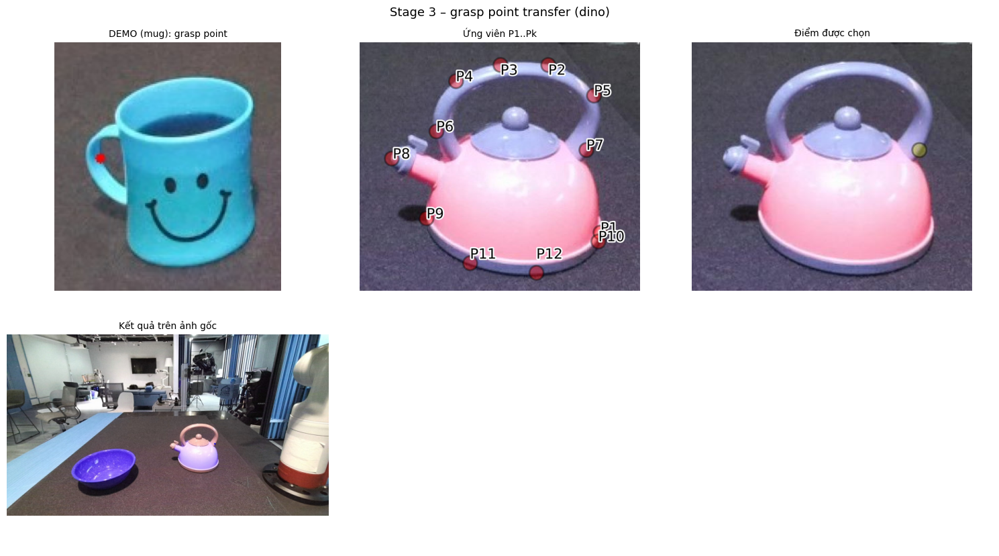

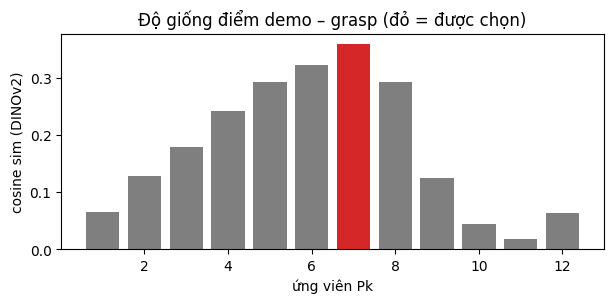

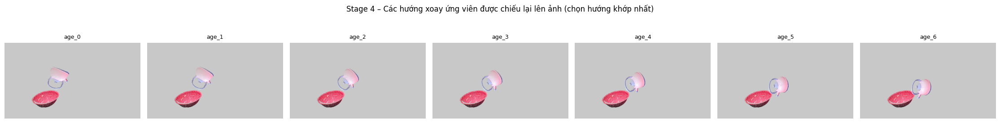

Điểm 3D (hệ target) – function/center/grasp tại pose đầu và pose tiếp xúc:


,x,y,z
function_init,0.276,0.065,0.112
center_init,0.280,0.064,0.046
grasp_init,0.343,0.060,0.046
function_func,0.073,0.016,0.069
center_func,0.116,0.057,0.098
grasp_func,0.099,0.043,0.156


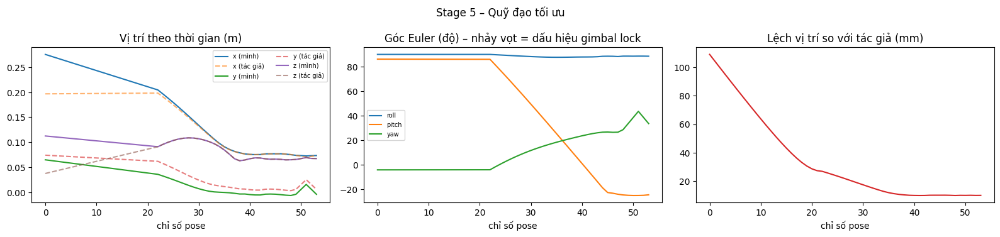

In [ ]:
import glob
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import open3d as o3d
from PIL import Image
from IPython.display import display

def _rd(d, rel):
    p = f"{d}/{rel}"
    return Image.open(p) if os.path.exists(p) else None

def _grid(d, panels, ncols=3, figsize=None, title=""):
    n = len(panels); nrows = (n + ncols - 1) // ncols
    fig, ax = plt.subplots(nrows, ncols, figsize=figsize or (5 * ncols, 4.2 * nrows)); ax = np.array(ax).reshape(-1)
    for a in ax: a.axis("off")
    for a, (t, rel) in zip(ax, panels):
        im = _rd(d, rel)
        if im is not None: a.imshow(im)
        else: a.text(0.5, 0.5, "thiếu file", ha="center")
        a.set_title(t, fontsize=10)
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()

def _plot_ply(items, title, max_pts=15000):
    """items: list[(đường dẫn .ply, tên, kích thước điểm)] -> Plotly 3D."""
    fig = go.Figure()
    for path, name, size in items:
        if not os.path.exists(path): continue
        pc = o3d.io.read_point_cloud(path); pts = np.asarray(pc.points)
        if len(pts) == 0: continue
        col = np.clip(np.asarray(pc.colors), 0, 1) if pc.has_colors() else None
        sel = np.random.RandomState(0).choice(len(pts), min(max_pts, len(pts)), replace=False)
        marker = dict(size=size)
        if col is not None: marker["color"] = [f"rgb({int(r*255)},{int(g*255)},{int(b*255)})" for r, g, b in col[sel]]
        fig.add_trace(go.Scatter3d(x=pts[sel, 0], y=pts[sel, 1], z=pts[sel, 2], mode="markers", marker=marker, name=name))
    fig.update_layout(title=title, scene=dict(aspectmode="data"), margin=dict(l=0, r=0, b=0, t=40), height=550); fig.show()

# ---------- Stage 1: detection + segmentation + hệ toạ độ target ----------
def viz_detect(name):
    d = f"{REPO}/test_data/{name}"
    _grid(d, [("OWLv2: bbox tool", "detection_output/tool_bbox.png"), ("OWLv2: bbox target", "detection_output/target_bbox.png"),
              ("Mask tool", "detection_output/tool_mask.png"), ("Mask target", "detection_output/target_mask.png")],
          ncols=4, title="Stage 1 – Detection & Segmentation")
    _plot_ply([(f"{d}/cam_to_target_trans_output/transformed_scene_point_cloud.ply", "scene (đã xoay, gốc tại target)", 1.5),
               (f"{d}/cam_to_target_trans_output/target_point_cloud_with_aabb_corners.ply", "target + 8 góc AABB", 3)],
              "Stage 1 – Point cloud sau khi fit mặt bàn (RANSAC) và đổi sang hệ toạ độ target")

# ---------- Stage 2/3: function point & grasp point ----------
def _viz_keypoint(name, kind):
    d = f"{REPO}/test_data/{name}"
    if kind == "function":
        out = "func_point_transfer_output"
        panels = [("DEMO (mug): function point", f"{out}/demo_tool_func_point_init_vis.jpg"), ("TEST (teapot): crop", f"{out}/test_tool_crop.png"),
                  ("Mask crop tool test", f"{out}/test_tool_mask_crop.png"), ("Ứng viên P1..Pk", f"{out}/visual_prompting_candidates.png"),
                  ("Điểm được chọn", f"{out}/visual_prompting_result.png"), ("Kết quả trên ảnh gốc", f"{out}/test_init_frame_func_point_vis.jpg")]
    else:
        out = "grasp_transfer_output"
        panels = [("DEMO (mug): grasp point", f"{out}/demo_init_frame_grasp_point_vis.jpg"), ("Ứng viên P1..Pk", f"{out}/visual_prompting_candidates.png"),
                  ("Điểm được chọn", f"{out}/visual_prompting_result.png"), ("Kết quả trên ảnh gốc", f"{out}/test_init_frame_grasp_point_vis.jpg")]
    _grid(d, panels, ncols=3, title=f"Stage {'2' if kind == 'function' else '3'} – {kind} point transfer ({RUN_MODE if 'main' in name else 'run'})")
    if kind in SEL and SEL[kind].get("sims"):                      # chỉ có ở chế độ DINO
        s = np.array(SEL[kind]["sims"]); plt.figure(figsize=(7, 2.8))
        plt.bar(range(1, len(s) + 1), s, color=["tab:red" if i == SEL[kind]["idx"] else "tab:gray" for i in range(len(s))])
        plt.xlabel("ứng viên Pk"); plt.ylabel("cosine sim (DINOv2)"); plt.title(f"Độ giống điểm demo – {kind} (đỏ = được chọn)"); plt.show()

def viz_func(name):  _viz_keypoint(name, "function")
def viz_grasp(name): _viz_keypoint(name, "grasp")

# ---------- Stage 4: căn chỉnh pose tool ----------
def viz_pose(name):
    d = f"{REPO}/test_data/{name}/tool_pose_transfer_output"
    imgs = sorted(glob.glob(f"{d}/test_projected_image_*.png"))
    if imgs:
        fig, ax = plt.subplots(1, len(imgs), figsize=(3.2 * len(imgs), 3.2)); ax = np.array(ax).reshape(-1)
        for a, p in zip(ax, imgs): a.imshow(Image.open(p)); a.set_title(os.path.basename(p)[-9:-4], fontsize=9); a.axis("off")
        fig.suptitle("Stage 4 – Các hướng xoay ứng viên được chiếu lại lên ảnh (chọn hướng khớp nhất)"); plt.tight_layout(); plt.show()
    _plot_ply([(f"{d}/demo_func_center_grasp_points.ply", "demo: function/center/grasp", 4),
               (f"{d}/test_func_grasp_center_points_aligned.ply", "test: sau khi căn chỉnh", 4),
               (f"{d}/refined_test_tool_pc.ply", "point cloud tool test (đã căn)", 1.5)],
              "Stage 4 – Điểm chức năng của demo vs tool test sau khi căn pose")
    trk = _j(f"{d}/test_tool_track.json")
    print("Điểm 3D (hệ target) – function/center/grasp tại pose đầu và pose tiếp xúc:")
    display(pd.DataFrame({k: np.round(v, 3) for k, v in trk.items()}, index=["x", "y", "z"]).T)

# ---------- Stage 5: quỹ đạo ----------
def viz_traj(name):
    P, E = load_traj(f"{REPO}/test_data/{name}/tool_traj_transfer_output/test_tool_trajectory.json")
    Pr, Er = load_traj(f"{REF_DIR}/tool_traj_transfer_output/test_tool_trajectory.json")
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); t = np.arange(len(P))
    for k, lab in enumerate("xyz"):
        ax[0].plot(t, P[:, k], label=f"{lab} (mình)"); ax[0].plot(t[:len(Pr)], Pr[:len(P), k], "--", alpha=.6, label=f"{lab} (tác giả)")
    ax[0].set_title("Vị trí theo thời gian (m)"); ax[0].legend(fontsize=7, ncol=2)
    for k, lab in enumerate(["roll", "pitch", "yaw"]): ax[1].plot(t, np.degrees(np.unwrap(E[:, k])), label=lab)
    ax[1].set_title("Góc Euler (độ) – nhảy vọt = dấu hiệu gimbal lock"); ax[1].legend(fontsize=7)
    n = min(len(P), len(Pr)); ax[2].plot(np.linalg.norm(P[:n] - Pr[:n], axis=1) * 1000, c="tab:red")
    ax[2].set_title("Lệch vị trí so với tác giả (mm)"); [a.set_xlabel("chỉ số pose") for a in ax]
    fig.suptitle("Stage 5 – Quỹ đạo tối ưu"); plt.tight_layout(); plt.show()
    plot_traj_3d(name) if "plot_traj_3d" in globals() else None

def viz_all(name):
    for f in (viz_detect, viz_func, viz_grasp, viz_pose, viz_traj): f(name)

viz_detect(main_name)
viz_func(main_name)
viz_grasp(main_name)
viz_pose(main_name)
viz_traj(main_name)

## 10. Thí nghiệm
Câu hỏi: **thành phần nào ảnh hưởng nhiều nhất tới chất lượng quỹ đạo?**
- `mask`: SAM thật vs. mask hình chữ nhật (stub bản chạy trước của bạn)
- `n_cand`: số điểm ứng viên cho visual prompting (8 / 12 / 16)
- (nếu có key) `gpt4o` lặp `N_GPT_TRIALS` lần để đo độ ổn định của VLM

Mỗi cấu hình chạy khoảng vài chục giây trên T4.

#### Chạy ablation

▶ abl_dino_k8_sam ... 

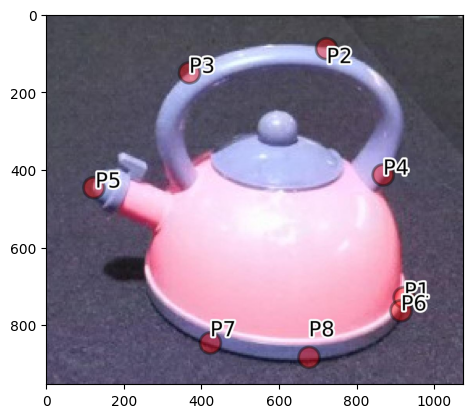

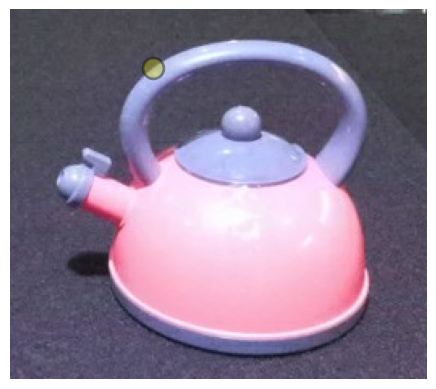

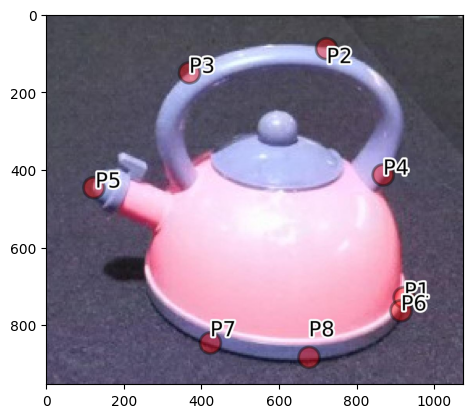

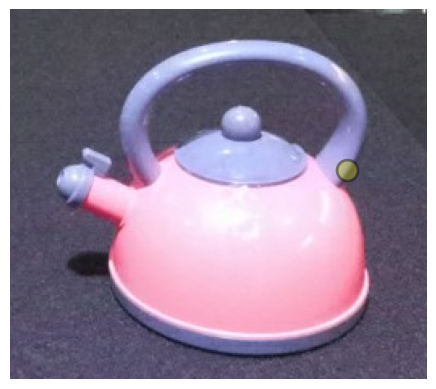

OK (28s)
▶ abl_dino_k12_sam ... 

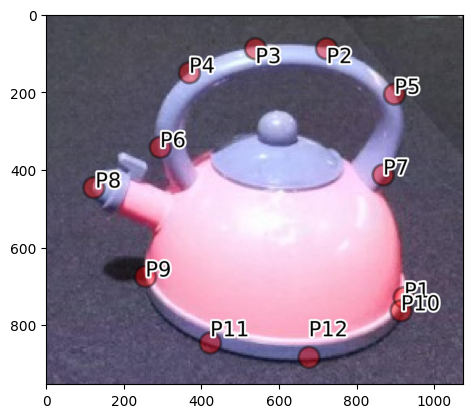

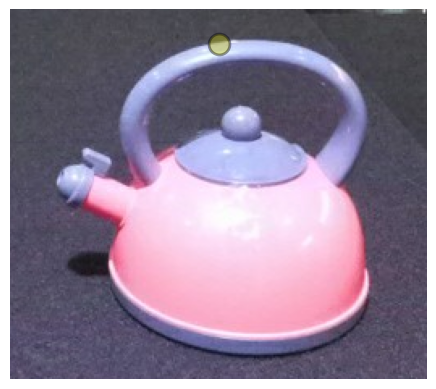

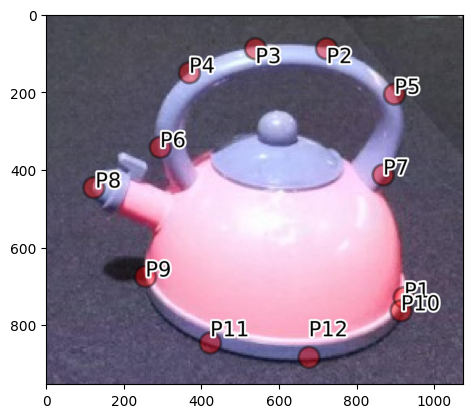

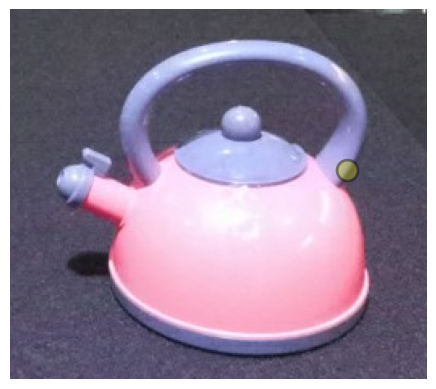

OK (25s)
▶ abl_dino_k16_sam ... 

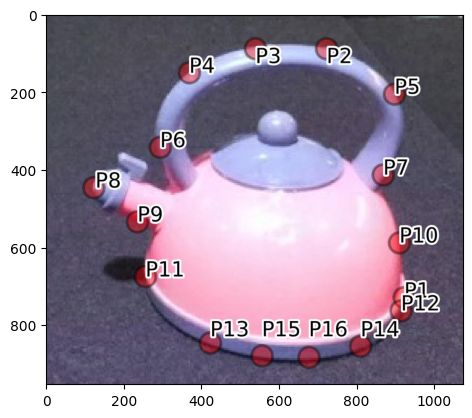

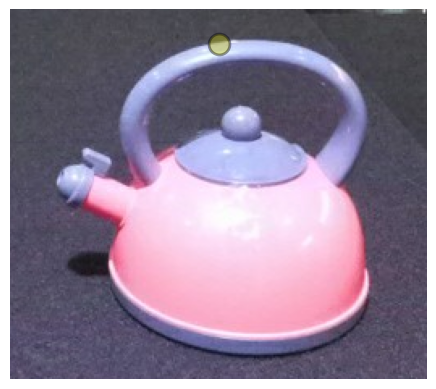

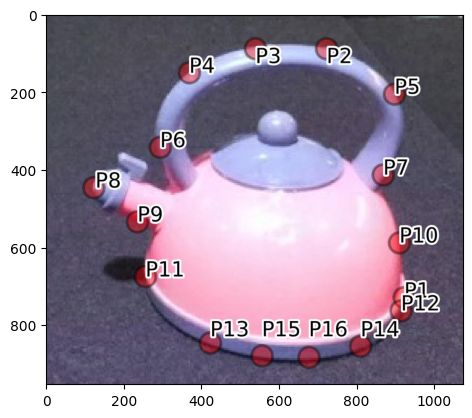

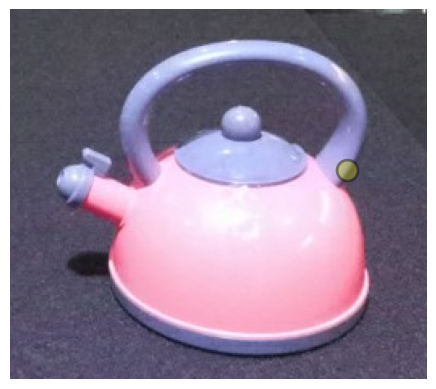

OK (25s)
▶ abl_dino_k8_box ... 

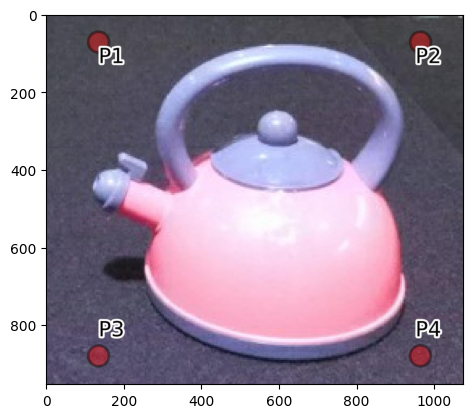

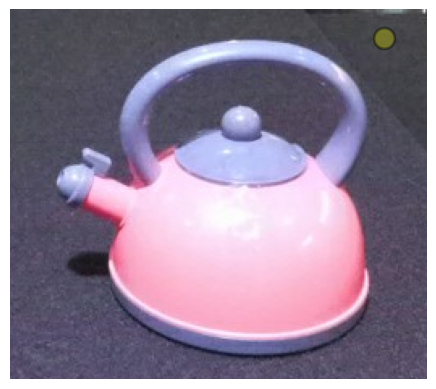

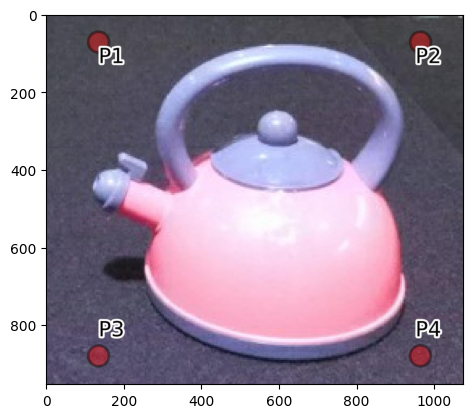

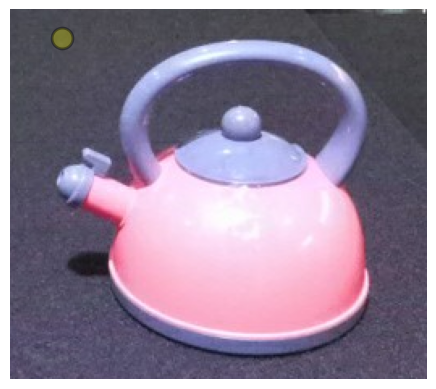

FAIL @ tool_pose (11s)
▶ abl_dino_k12_box ... 

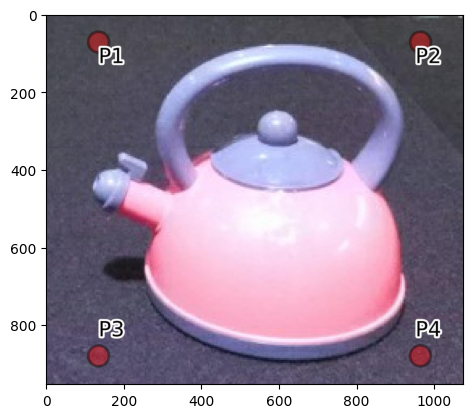

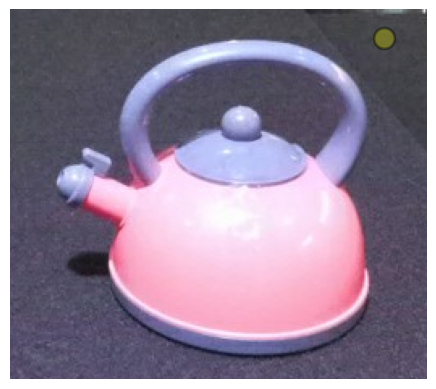

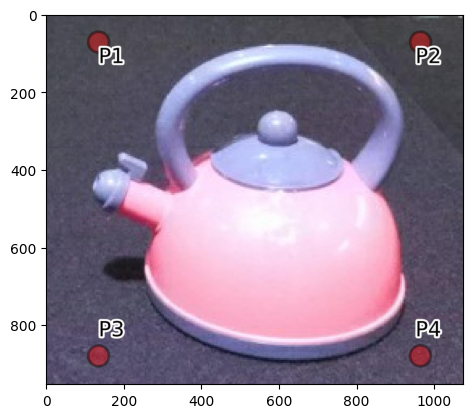

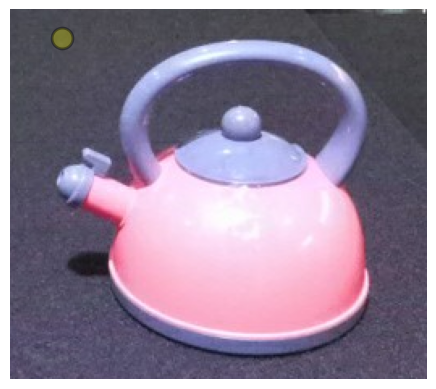

FAIL @ tool_pose (11s)
▶ abl_dino_k16_box ... 

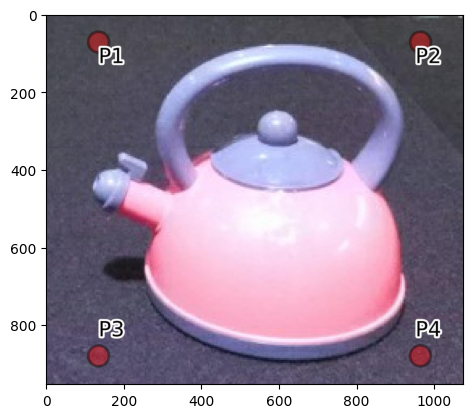

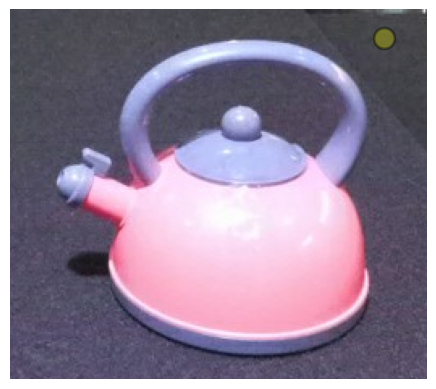

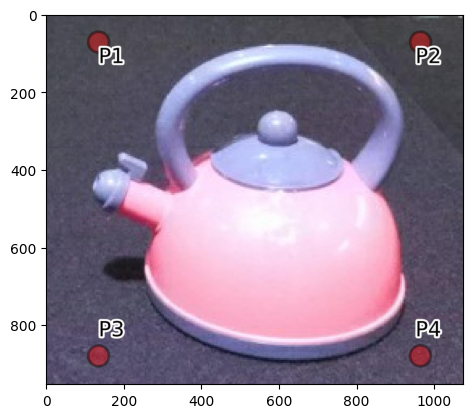

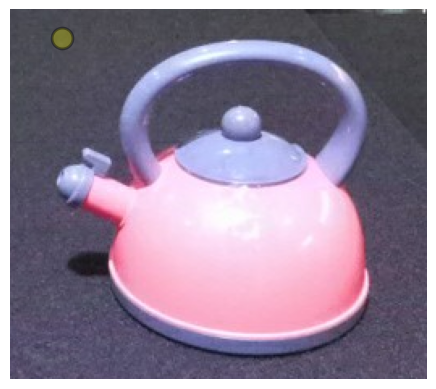

FAIL @ tool_pose (11s)


,run,selector,n_cand,mask,ok,failed_stage,iou_tool,iou_target,func_err_%diag,grasp_err_%diag,traj_pos_err_m,traj_rot_err_deg,pour_proxy_ok,pour_offset,margin_function,t_total
0,abl_dino_k8_sam,dino,8,sam,True,,0.952,0.994,33.624,39.998,0.023,36.170,True,0.886,0.026,27.622
1,abl_dino_k12_sam,dino,12,sam,True,,0.952,0.994,48.203,39.998,0.034,57.906,True,0.896,0.040,25.261
2,abl_dino_k16_sam,dino,16,sam,True,,0.952,0.994,48.203,39.998,0.034,57.983,True,0.896,0.040,25.295
3,abl_dino_k8_box,dino,8,box,False,tool_pose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.009,11.295
4,abl_dino_k12_box,dino,12,box,False,tool_pose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.009,11.111
5,abl_dino_k16_box,dino,16,box,False,tool_pose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.009,10.764


In [ ]:
EXPS = [dict(run_name=f"abl_dino_k{k}_{m}", selector="dino", n_cand=k, mask_mode=m)
        for m in ["sam", "box"] for k in [8, 12, 16]]
if HAS_KEY:
    EXPS += [dict(run_name=f"abl_gpt4o_t{t}", selector="gpt4o", n_cand=12, mask_mode="sam") for t in range(N_GPT_TRIALS)]

rows = []
for e in EXPS:
    print("▶", e["run_name"], end=" ... ")
    rr = run_pipeline(**e)
    rows.append({**rr, **(evaluate(e["run_name"]) if rr["ok"] else {})})
    print("OK" if rr["ok"] else f"FAIL @ {rr['failed_stage']}", f"({rr['t_total']:.0f}s)")

res_df = pd.DataFrame(rows)
cols = ["run", "selector", "n_cand", "mask", "ok", "failed_stage", "iou_tool", "iou_target", "func_err_%diag",
        "grasp_err_%diag", "traj_pos_err_m", "traj_rot_err_deg", "pour_proxy_ok", "pour_offset", "margin_function", "t_total"]
res_df = res_df[[c for c in cols if c in res_df.columns]]
res_df.to_csv("/content/results.csv", index=False)
display(res_df.round(3))

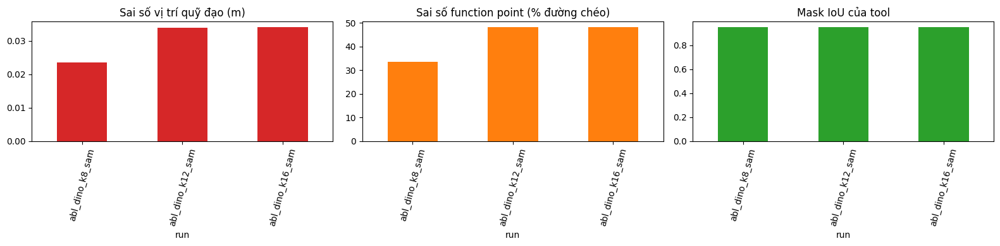

Thành công: 3/6 cấu hình | CSV: /content/results.csv
Pour-proxy đạt: 3 cấu hình


In [ ]:
# Biểu đồ tóm tắt
ok = res_df[res_df["ok"] == True]
if len(ok):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ok.plot.bar(x="run", y="traj_pos_err_m", ax=ax[0], legend=False, color="tab:red");  ax[0].set_title("Sai số vị trí quỹ đạo (m)")
    ok.plot.bar(x="run", y="func_err_%diag", ax=ax[1], legend=False, color="tab:orange"); ax[1].set_title("Sai số function point (% đường chéo)")
    ok.plot.bar(x="run", y="iou_tool", ax=ax[2], legend=False, color="tab:green");     ax[2].set_title("Mask IoU của tool")
    for a in ax: a.tick_params(axis="x", rotation=75)
    plt.tight_layout(); plt.show()
print(f"Thành công: {int(res_df['ok'].sum())}/{len(res_df)} cấu hình | CSV: /content/results.csv")
if "pour_proxy_ok" in res_df:
    print("Pour-proxy đạt:", int(res_df['pour_proxy_ok'].fillna(False).sum()), "cấu hình")

### Xem một ca thất bại

In [ ]:
bad = res_df[(res_df["ok"] == False)]
if len(bad):
    display(bad[["run", "failed_stage"]]); print("Lỗi:", rows[bad.index[0]]["error"])
else:
    worst = res_df.sort_values("traj_pos_err_m", ascending=False).iloc[0]["run"]
    print("Cấu hình lệch quỹ đạo nhiều nhất:", worst)
    show_run(worst); overlay_points(worst)

,run,failed_stage
3,abl_dino_k8_box,tool_pose
4,abl_dino_k12_box,tool_pose
5,abl_dino_k16_box,tool_pose


Lỗi: ValueError: Error: 3D grasp point not found.


## 11. Nhận xét kết quả thực nghiệm


> **Nhận xét:**

 Kết quả cho thấy phương pháp phụ thuộc rất lớn vào chất lượng phân đoạn mask. Các cấu hình sử dụng SAM (`_sam`) đều chạy thành công (`ok = True`) với độ trùng khớp mặt nạ cao (Tool IoU = 0.952, Target IoU = 0.994) và đạt tiêu chí rót (`pour_proxy_ok = True`). Trong đó, cấu hình $k = 8$ (`abl_dino_k8_sam`) mang lại hiệu quả tốt nhất với sai số điểm chức năng (`33.624%`) và sai số góc quay (`36.170°`) thấp hơn so với các mức $k$ lớn hơn. Ngược lại, toàn bộ các cấu hình sử dụng khung chữ nhật (`_box`) đều thất bại ở giai đoạn tính toán tư thế dụng cụ (`tool_pose`) do vùng nền bị lẫn vào đám mây điểm (point cloud), làm gián đoạn quá trình ước lượng tư thế 3D.

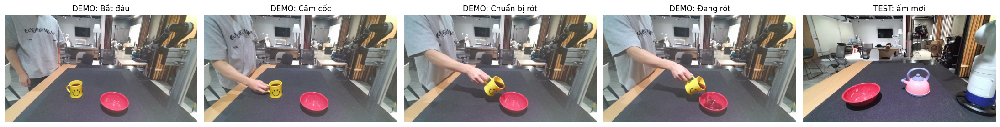

In [ ]:
frames = [("Bắt đầu", 0), ("Cầm cốc", 16), ("Chuẩn bị rót", 35), ("Đang rót", 51)]
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for a, (t, i) in zip(ax, frames):
    a.imshow(Image.open(f"{DEMO_DIR}/rgb/{i:05d}.jpg")); a.set_title(f"DEMO: {t}"); a.axis("off")
ax[4].imshow(Image.open(f"{REF_DIR}/rgb/00000.jpg")); ax[4].set_title("TEST: ấm mới"); ax[4].axis("off")
plt.tight_layout(); plt.show()